# Checking the Run Logs

In [1]:
import datetime as datetime

import pandas as pd
import numpy as np
import h5py as h5

import scipy
import matplotlib as mpl
import matplotlib.pyplot as plt


In [69]:
# boundary values
# semi major axis a
a_max = 4
a_min = 1.0
# eccentricity e
e_min = 0.1
e_max = 0.14
# inclination i
i_min = 18.1
i_max = 19.6

# indices in the particles array 
A = 6
E = 7
I = 8

particles_assigned = pd.read_hdf('../asteroid_data/sim_data/luthera_7p_5t_c/clone_assignments.h5')

luth_run = h5.File('../asteroid_data/sim_data/luthera_7p_5t_c/results_20230418/pvals_20230418_1529_0.h5',"r")

In [70]:
print(f"Sim number:{luth_run.attrs['simulation']} Years modelled:{luth_run.attrs['int_length']:0.1e} Walltime:{datetime.timedelta(seconds=luth_run.attrs['clock_time'])}")

sim_particles = particles_assigned[particles_assigned['sim_no']==luth_run.attrs['simulation']]

sim_particles

Sim number:0 Years modelled:1.0e+09 Walltime:1 day, 6:46:55.143222


,sim_no,particle_number,ast_name,particle_types
0,0,9,1303,"[Xcp, Ycp, Zcp, VXcp, VYcp, VZcp]"
11414,0,10,331978,"[Xcm, Ycp, Zcp, VXcm, VYcm, VZcm]"
22828,0,11,586547,"[Xcp, Ycp, Zcm, VXcm, VYcp, VZcm]"
34242,0,12,2016 LZ6,"[Xcm, Ycm, Zcp, VXcm, VYcp, VZcp]"
45656,0,13,2007 YF97,"[Xcp, Ycm, Zcm, VXcp, VYcm, VZcp]"


In [71]:
int_values = luth_run['integration_time_values'][()]
part_values = luth_run['test_particle_values'][()]

In [130]:
outside = np.where(((part_values[:,:,A] > a_max) | (part_values[:,:,A] < a_min)))
print(len(outside[0]))
print(int_values[np.min(outside[0])]/(2*np.pi))
print(np.unique(outside[1]))

for p_num in np.unique(outside[1]):
    print(sim_particles[sim_particles['particle_number'] == p_num + 9][['ast_name','particle_types']].tolist())
    p, n = sim_particles[sim_particles['particle_number'] == p_num + 9][['ast_name','particle_types']].array[0]
    print(p, ''.join(n))


398396
601665008.6760266
[1]


AttributeError: 'DataFrame' object has no attribute 'tolist'

In [80]:
part_means[:,6:]

array([[  3.21395267,   0.11951855,   0.32597056],
       [-37.66627759,   0.48919922,   0.27544058],
       [  3.21452871,   0.12810192,   0.33304494],
       [  3.06694487,   0.08732598,   0.18656865],
       [  2.31883504,   0.13162798,   0.0536203 ]])

In [81]:
part_values[:,:,6:].shape

(1000000, 5, 3)

In [82]:
s0003_z = scipy.stats.zscore(part_values[:,:,6:],0)

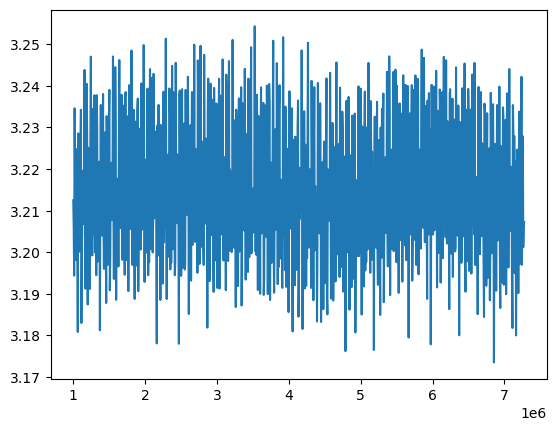

In [83]:
plt.plot(int_values[:1000], part_values[:1000,0,6])

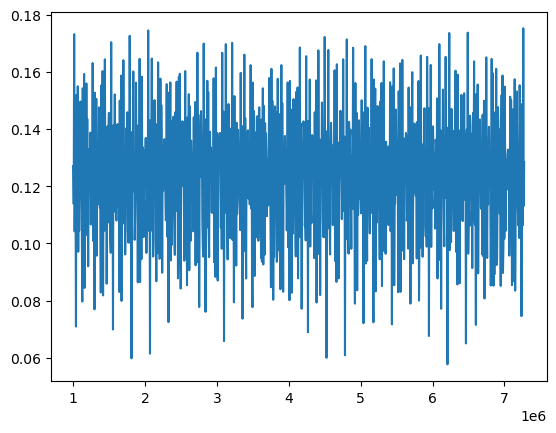

In [84]:
plt.plot(int_values[:1000], part_values[:1000,0,7])

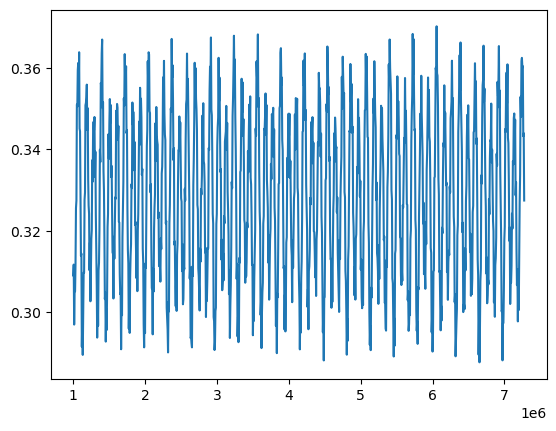

In [85]:
plt.plot(int_values[:1000], part_values[:1000,0,8])